# Transfer Learning e Fine-Tuning em CNN — Classificação de Resíduos Sólidos (RealWaste)

**Disciplina:** Inteligência Computacional / Machine Learning — Profa. Polyana Santos Fonseca Nascimento — CESUPA

## Integrantes
- _(preencher)_
- _(preencher)_

## Declaração de uso de IA Generativa
| Item | Descrição |
|---|---|
| (1) Ferramenta | Claude Code (Anthropic) — _(completar com outras, se houver)_ |
| (2) Finalidade | Planejamento do roteiro, verificação do dataset (contagens e duplicatas), esboço de código e de textos explicativos |
| (3) Extensão | _(a equipe deve estimar, ex.: "cerca de X% do código inicial; análises revisadas e reescritas pela equipe")_ |
| (4) Validação | _(ex.: execução de todas as células, conferência dos números com o artigo do dataset, revisão de cada decisão pela equipe)_ |


## Dataset e justificativa

**RealWaste** — UCI Machine Learning Repository (id 908). Licença CC BY-NC-SA 4.0.
Fonte: https://archive.ics.uci.edu/dataset/908/realwaste

Referência: SINGLE, S.; IRANMANESH, S.; RAAD, R. *RealWaste: A Novel Real-Life Data Set for Landfill Waste Classification Using Deep Learning*. **Information**, v. 14, n. 12, p. 633, 2023.

**Contexto:** fotos de resíduos reais recebidos no aterro Whyte's Gully (Wollongong, Austrália), capturadas na esteira de triagem.
**Target:** classe do material do resíduo (9 classes).
**Finalidade:** apoiar a triagem automatizada em centrais de reciclagem: uma câmera sobre a esteira identifica o material e direciona o resíduo, reduzindo trabalho manual insalubre e contaminação dos lotes recicláveis.

**Por que este dataset:** imagens de campo (sujas, amassadas, sobrepostas), e não de estúdio; publicação recente em repositório confiável;
classes com confusão realista (papel × papelão, plástico × rejeito), o que torna a comparação entre estratégias e a explicabilidade informativas.


## Configuração e dependências

Ambiente: Python 3.12, execução em CPU. Versões fixadas em `requirements.txt`
(torch 2.15 CPU, torchvision 0.29, numpy, pandas, scikit-learn, matplotlib, pillow). Instalação: `pip install -r requirements.txt`.

Dados: extrair o zip do RealWaste (UCI) em `data/`, resultando em `data/realwaste-main/RealWaste/<classe>/*.jpg`.


In [1]:
from pathlib import Path
import hashlib
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RAW_DIR = Path("data/realwaste-main/RealWaste")   # imagens originais
DATA_DIR = Path("data/realwaste_256")             # cópia redimensionada usada no treino

## 1. Arquitetura: MobileNetV2

**Referência:** SANDLER, M.; HOWARD, A.; ZHU, M.; ZHMOGINOV, A.; CHEN, L.-C. *MobileNetV2: Inverted Residuals and Linear Bottlenecks*.
In: **IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)**, 2018, p. 4510–4520. arXiv:1801.04381. (Google)

**Motivação:** CNNs como VGG e ResNet são precisas, mas caras demais para celulares e dispositivos embarcados.
A MobileNetV2 atinge ~72% de acurácia top-1 no ImageNet com **3,5 M de parâmetros** (ResNet50: 25,6 M, ~76%).
Isso combina com a finalidade do trabalho: um classificador que poderia rodar numa câmera barata sobre a esteira de triagem.

### Principal inovação em relação a uma CNN convencional — convolução separável em profundidade
Uma convolução 3×3 convencional filtra o espaço **e** mistura canais ao mesmo tempo. A MobileNet separa em duas etapas:
1. **Depthwise 3×3:** um filtro por canal (só olha a vizinhança espacial).
2. **Pointwise 1×1:** combina os canais.

O custo cai para aproximadamente $\frac{1}{C_{out}} + \frac{1}{k^2}$ do original — cerca de **8 a 9× menos operações** com $k=3$, com pequena perda de acurácia.

### Diferencial da versão V2 (em relação à V1)
- **Residual invertido:** o bloco da ResNet é *largo → estreito → largo*; o da V2 é *estreito → largo → estreito*.
  Uma 1×1 **expande** os canais (fator $t=6$), a depthwise 3×3 filtra no espaço largo (barato, por ser depthwise) e outra 1×1 **projeta** de volta.
  O atalho (skip connection) liga as extremidades estreitas, economizando memória.
- **Gargalo linear:** a projeção final **não tem ReLU**. Em poucos canais, zerar valores negativos destrói informação de forma irreversível;
  em muitos canais há redundância. Nas demais camadas usa-se **ReLU6** ($\min(\max(0,x),6)$), robusta em baixa precisão numérica.

O diagrama abaixo compara os dois blocos (largura das barras proporcional ao nº de canais):


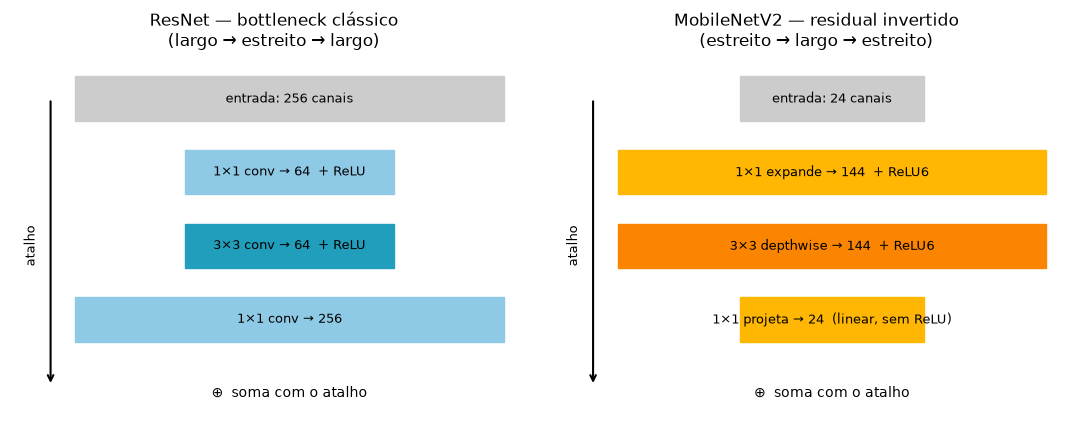

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
blocks = {
    "ResNet — bottleneck clássico\n(largo → estreito → largo)": [
        ("entrada: 256 canais", 256, "#cccccc"),
        ("1×1 conv → 64  + ReLU", 64, "#8ecae6"),
        ("3×3 conv → 64  + ReLU", 64, "#219ebc"),
        ("1×1 conv → 256", 256, "#8ecae6")],
    "MobileNetV2 — residual invertido\n(estreito → largo → estreito)": [
        ("entrada: 24 canais", 24, "#cccccc"),
        ("1×1 expande → 144  + ReLU6", 144, "#ffb703"),
        ("3×3 depthwise → 144  + ReLU6", 144, "#fb8500"),
        ("1×1 projeta → 24  (linear, sem ReLU)", 24, "#ffb703")],
}
for ax, (title, layers) in zip(axes, blocks.items()):
    widest = max(ch for _, ch, _ in layers)
    for i, (text, ch, color) in enumerate(layers):
        width, y = 0.3 + 0.65 * ch / widest, len(layers) - i
        ax.add_patch(plt.Rectangle((0.5 - width / 2, y - 0.3), width, 0.6, color=color))
        ax.text(0.5, y, text, ha="center", va="center", fontsize=9)
    ax.text(0.5, 0, "⊕  soma com o atalho", ha="center", va="center", fontsize=10)
    ax.annotate("", xy=(-0.03, 0.1), xytext=(-0.03, len(layers)), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(-0.09, len(layers) / 2, "atalho", rotation=90, va="center", fontsize=9)
    ax.set_xlim(-0.12, 1.05); ax.set_ylim(-0.5, len(layers) + 0.6)
    ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

### Estrutura completa (entrada 224×224×3)

| `features[i]` (torchvision) | operação | canais de saída | repetições | stride | resolução de saída |
|---|---|---|---|---|---|
| 0 | conv 3×3 | 32 | 1 | 2 | 112×112 |
| 1 | bloco residual invertido ($t=1$) | 16 | 1 | 1 | 112×112 |
| 2–3 | bloco ($t=6$) | 24 | 2 | 2 | 56×56 |
| 4–6 | bloco ($t=6$) | 32 | 3 | 2 | 28×28 |
| 7–10 | bloco ($t=6$) | 64 | 4 | 2 | 14×14 |
| 11–13 | bloco ($t=6$) | 96 | 3 | 1 | 14×14 |
| 14–16 | bloco ($t=6$) | 160 | 3 | 2 | 7×7 |
| 17 | bloco ($t=6$) | 320 | 1 | 1 | 7×7 |
| 18 | conv 1×1 | 1280 | 1 | 1 | 7×7 |
| `classifier` | média global → Dropout(0,2) → Linear | 1000 (ImageNet) | | | |

O atalho só existe quando o bloco mantém resolução e nº de canais (stride 1); no primeiro bloco de cada estágio ele é omitido.

**Implementação:** PyTorch + torchvision, `mobilenet_v2` com pesos `IMAGENET1K_V2` (72,15% top-1 no ImageNet).
Para comparação: a MobileNetV3 (2019) é posterior e foi obtida por busca automática de arquitetura (NAS), acrescentando squeeze-and-excitation e h-swish.


## 2. Análise inicial e pré-processamento dos dados

### 2.1 Inventário das imagens

In [3]:
df = pd.DataFrame([{"path": p.relative_to(RAW_DIR).as_posix(), "label": p.parent.name}
                   for p in sorted(RAW_DIR.glob("*/*.jpg"))])
CLASSES = sorted(df.label.unique())
counts = df.label.value_counts()
print(f"{len(df)} imagens, {len(CLASSES)} classes")
print(f"Razão maior/menor classe: {counts.max() / counts.min():.2f}")
counts.to_frame("imagens")

4752 imagens, 9 classes
Razão maior/menor classe: 2.90


,imagens
label,
Plastic,921
Metal,790
Paper,500
Miscellaneous Trash,495
Cardboard,461
Vegetation,436
Glass,420
Food Organics,411
Textile Trash,318


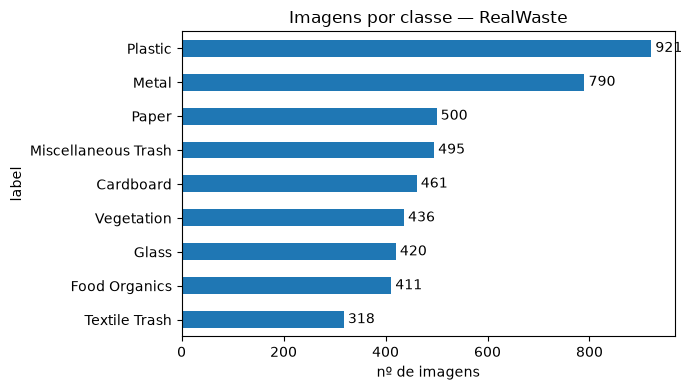

In [4]:
ax = counts.sort_values().plot.barh(figsize=(7, 4), color="tab:blue")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("nº de imagens")
ax.set_title("Imagens por classe — RealWaste")
plt.tight_layout()
plt.show()

### 2.2 Dimensões, canais e duplicatas

In [5]:
def image_info(rel_path):
    data = (RAW_DIR / rel_path).read_bytes()
    with Image.open(RAW_DIR / rel_path) as im:
        return im.width, im.height, im.mode, hashlib.md5(data).hexdigest()

df[["width", "height", "mode", "md5"]] = [image_info(p) for p in df.path]
print("Tamanhos (largura x altura):", df.groupby(["width", "height"]).size().to_dict())
print("Modos de cor:", df["mode"].value_counts().to_dict())
print("Arquivos duplicados (mesmo conteúdo):", df.md5.duplicated().sum())

Tamanhos (largura x altura): {(524, 524): 4752}
Modos de cor: {'RGB': 4752}
Arquivos duplicados (mesmo conteúdo): 0


### 2.3 Exemplos por classe

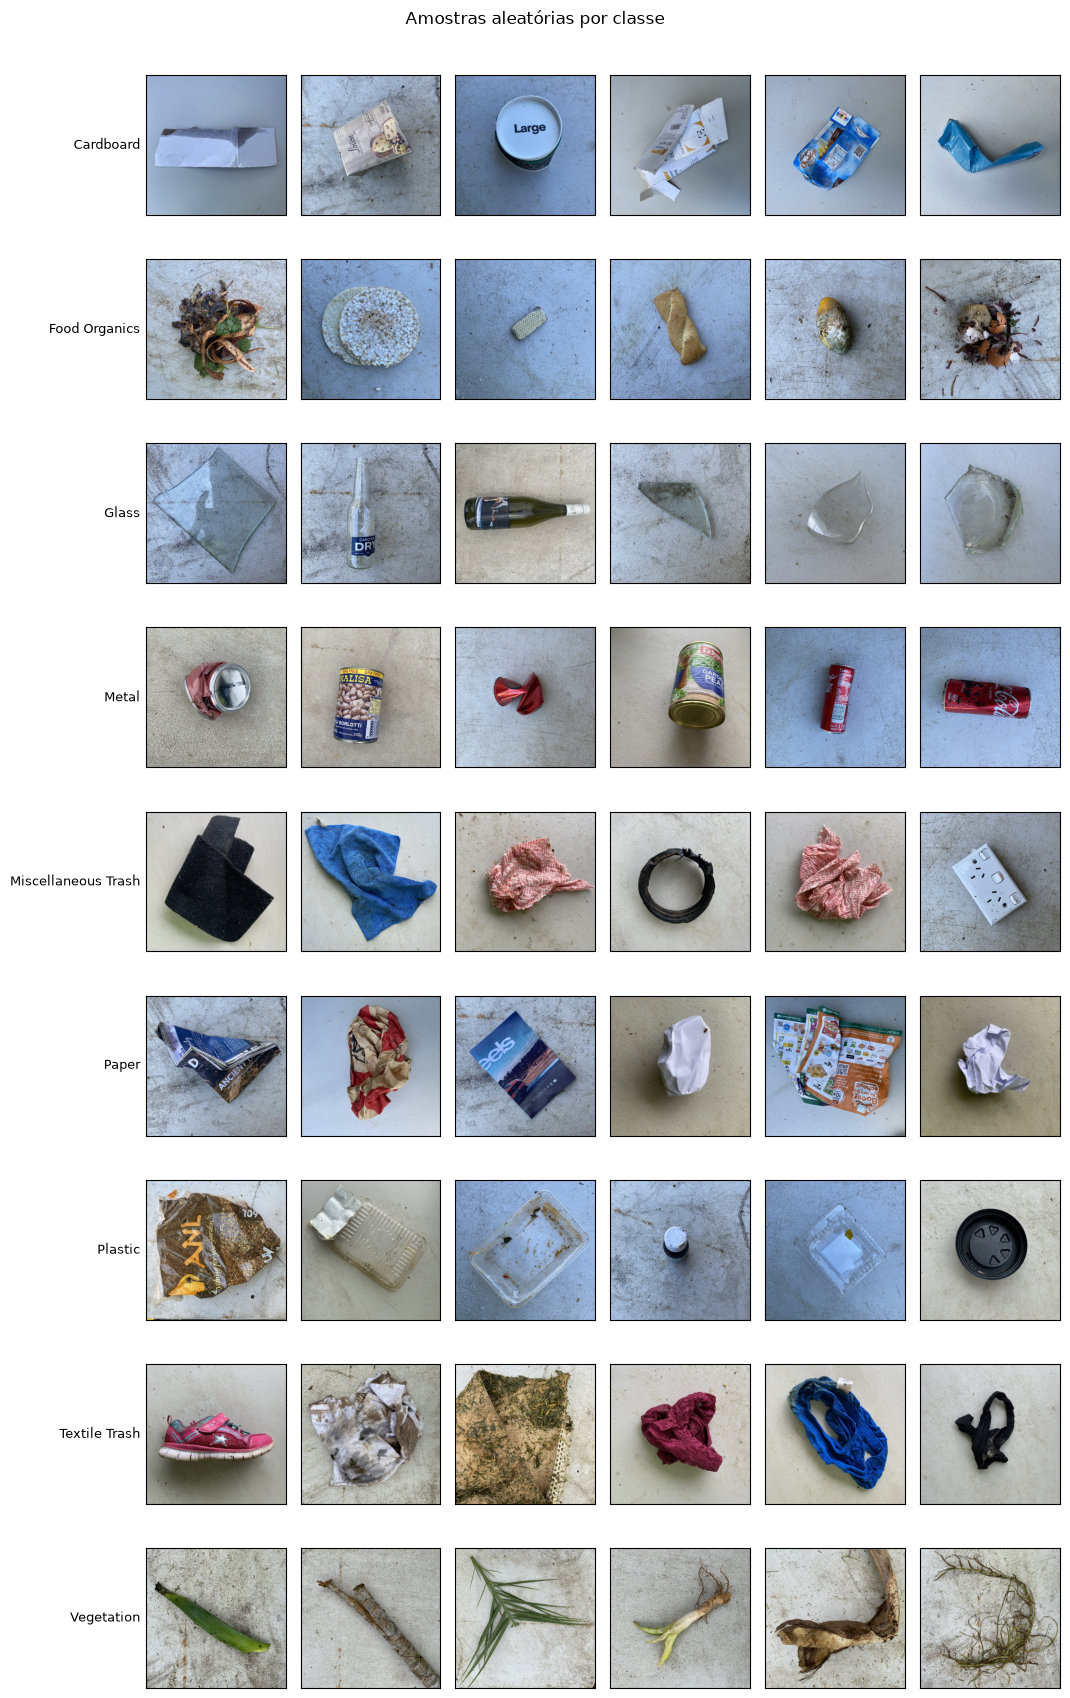

In [6]:
n_cols = 6
fig, axes = plt.subplots(len(CLASSES), n_cols, figsize=(n_cols * 1.8, len(CLASSES) * 1.9))
for row, cls in zip(axes, CLASSES):
    sample = df[df.label == cls].sample(n_cols, random_state=SEED)
    for ax, p in zip(row, sample.path):
        ax.imshow(Image.open(RAW_DIR / p))
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Amostras aleatórias por classe", y=1.0)
plt.tight_layout()
plt.show()

**Observações da análise inicial**

- **Dados íntegros:** 4.752 imagens, todas 524×524 e RGB, sem arquivos duplicados — não é preciso tratar canais nem remover imagens.
- **Fundo constante:** quase todas as fotos mostram um objeto isolado sobre o mesmo piso de concreto. O fundo não diferencia as classes,
  então o modelo *deveria* olhar para o objeto — hipótese a verificar com o Grad-CAM (Etapa 6).
- **Iluminação variável:** a temperatura de cor muda entre fotos (tons azulados × amarelados). Isso justifica um *color jitter* leve no aumento de dados.
- **Orientação arbitrária:** objetos aparecem em qualquer rotação → flips e rotações são aumentos seguros.
- **Ambiguidades de rótulo já visíveis:** em *Cardboard* aparecem embalagens e copos que parecem papel ou plástico; em *Miscellaneous Trash* há panos
  muito parecidos com *Textile Trash*; *Paper* inclui embalagens com aparência plástica. São candidatos naturais às principais confusões do modelo.
- **Desbalanceamento moderado** (Plastic 921 × Textile Trash 318, razão 2,9) → pesos por classe na loss e F1-macro como métrica principal.


### 2.4 Redimensionamento prévio (cache em 256×256)

Todas as imagens são quadradas 524×524. Os pesos pré-treinados do torchvision esperam entrada de 224×224 (após `Resize(256)` + `CenterCrop(224)`).
Redimensionar **uma única vez** para 256×256 e salvar evita decodificar e reduzir a imagem grande a cada época — importante porque o treino roda em CPU.
É uma transformação determinística aplicada igualmente a todas as imagens, sem uso de estatísticas dos dados, portanto **não causa vazamento** entre treino e teste.


In [7]:
assert (df.width == df.height).all(), "há imagens não quadradas — o resize distorceria"

for p in df.path:
    out = DATA_DIR / p
    if not out.exists():
        out.parent.mkdir(parents=True, exist_ok=True)
        Image.open(RAW_DIR / p).convert("RGB").resize((256, 256), Image.BILINEAR).save(out, quality=95)

print("Imagens no cache:", sum(1 for _ in DATA_DIR.glob("*/*.jpg")))

Imagens no cache: 4752


### 2.5 Divisão holdout estratificada (70 / 15 / 15)

O **teste é separado aqui e não é usado** em nenhum ajuste nem na escolha do modelo — só na Etapa 7.
A estratificação mantém a proporção das classes nos três conjuntos. A divisão fica salva em `splits.csv` para ser reproduzida exatamente.


In [8]:
train_df, rest = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=rest.label, random_state=SEED)

splits = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
splits[["path", "label", "split"]].to_csv("splits.csv", index=False)

assert splits.path.is_unique and len(splits) == len(df), "imagem repetida ou perdida entre conjuntos"
assert not splits.md5.duplicated().any(), "conteúdo repetido entre conjuntos"

pd.crosstab(splits.label, splits.split, margins=True)[["train", "val", "test", "All"]]

split,train,val,test,All
label,,,,
Cardboard,323,69,69,461
Food Organics,288,61,62,411
Glass,294,63,63,420
Metal,553,119,118,790
Miscellaneous Trash,346,74,75,495
Paper,350,75,75,500
Plastic,645,138,138,921
Textile Trash,222,48,48,318
Vegetation,305,66,65,436


In [9]:
# proporção de cada classe dentro de cada conjunto: deve ser praticamente igual nas três colunas
pd.crosstab(splits.label, splits.split, normalize="columns")[["train", "val", "test"]].mul(100).round(1)

split,train,val,test
label,,,
Cardboard,9.7,9.7,9.7
Food Organics,8.7,8.6,8.7
Glass,8.8,8.8,8.8
Metal,16.6,16.7,16.5
Miscellaneous Trash,10.4,10.4,10.5
Paper,10.5,10.5,10.5
Plastic,19.4,19.4,19.4
Textile Trash,6.7,6.7,6.7
Vegetation,9.2,9.3,9.1


### 2.6 Desbalanceamento: pesos por classe

A maior classe (Plastic) tem ~2,9× a menor (Textile Trash). Sem correção, o modelo tende a favorecer as classes grandes.
Usaremos **CrossEntropy ponderada** com peso inverso à frequência no **treino** (`n_total / (n_classes × n_classe)`): classes raras pesam mais no erro.


In [10]:
n_per_class = train_df.label.value_counts().reindex(CLASSES)
class_weights = len(train_df) / (len(CLASSES) * n_per_class)
class_weights.round(3).to_frame("peso")

,peso
label,
Cardboard,1.144
Food Organics,1.283
Glass,1.257
Metal,0.668
Miscellaneous Trash,1.068
Paper,1.056
Plastic,0.573
Textile Trash,1.665
Vegetation,1.212


### 2.7 Métricas e erros mais prejudiciais

| Métrica | Papel |
|---|---|
| **F1-macro** (validação) | **métrica principal e regra de seleção** — média simples do F1 das 9 classes; uma classe pequena ruim derruba o valor |
| Acurácia | referência geral, mas otimista com desbalanceamento |
| Precisão e recall por classe | mostram *qual* material o modelo erra e em que direção |
| Matriz de confusão | mostra *para onde* vai cada erro |

**Erros mais prejudiciais no contexto da triagem:**
- **Reciclável classificado como rejeito/orgânico** (Glass, Metal, Plastic, Paper, Cardboard → Miscellaneous Trash, Food Organics, Vegetation): material de valor vai para o aterro → acompanhar o **recall** das classes recicláveis.
- **Rejeito/orgânico classificado como reciclável** (ex.: Food Organics → Paper): contamina o lote reciclável e pode inutilizá-lo → acompanhar a **precisão** das classes recicláveis.

A matriz de confusão permite localizar exatamente esses dois tipos de erro.


### 2.8 Transformações e pré-processamento esperado pelos pesos

**Validação/teste** usam exatamente o pré-processamento dos pesos `IMAGENET1K_V2` (`weights.transforms()`):
redimensiona o menor lado para 232, recorta o centro em **224×224**, converte para tensor em [0, 1] e **normaliza cada canal RGB** com média e desvio do ImageNet.
A rede aprendeu suas features com entradas nessa escala; outra normalização deslocaria as ativações e pioraria o transfer learning.

**Treino** recebe aumento de dados aleatório, refeito a cada época, para reduzir overfitting:
- `RandomResizedCrop(224, scale=(0.7, 1.0))`: recortes de 70–100% da área — o objeto continua visível, mas em escala/posição diferentes;
- flips horizontal e vertical: o resíduo cai na esteira em qualquer orientação (evitamos rotação livre para não criar cantos pretos artificiais);
- `ColorJitter` leve: compensa a variação de iluminação observada na análise inicial;
- mesma normalização do ImageNet no final.


In [11]:
import time

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2
from torchvision.transforms import v2
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score)

torch.manual_seed(SEED)
WEIGHTS = MobileNet_V2_Weights.IMAGENET1K_V2
MEAN, STD = WEIGHTS.transforms().mean, WEIGHTS.transforms().std

eval_tf = WEIGHTS.transforms()
train_tf = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(224, scale=(0.7, 1.0)),
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
print("Validação/teste:", eval_tf)

Validação/teste: ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


### 2.9 Datasets e DataLoaders

Cada classe recebe um índice fixo pela ordem alfabética (`CLASSES`). Essa correspondência índice ↔ classe será salva junto com o modelo final.
O carregador de teste **não é criado** aqui — o teste só será usado na Etapa 7.


In [12]:
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
BATCH_SIZE = 32

class WasteDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame.path.tolist()
        self.targets = frame.label.map(CLASS_TO_IDX).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(DATA_DIR / self.paths[i]) as im:
            return self.transform(im.convert("RGB")), self.targets[i]

train_loader = DataLoader(WasteDataset(train_df, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(WasteDataset(val_df, eval_tf), batch_size=64, shuffle=False, num_workers=4)
y_val = np.array(val_loader.dataset.targets)
print(CLASS_TO_IDX)
print(f"treino: {len(train_loader.dataset)} imagens / {len(train_loader)} batches | validação: {len(y_val)} imagens")

{'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}
treino: 3326 imagens / 104 batches | validação: 713 imagens


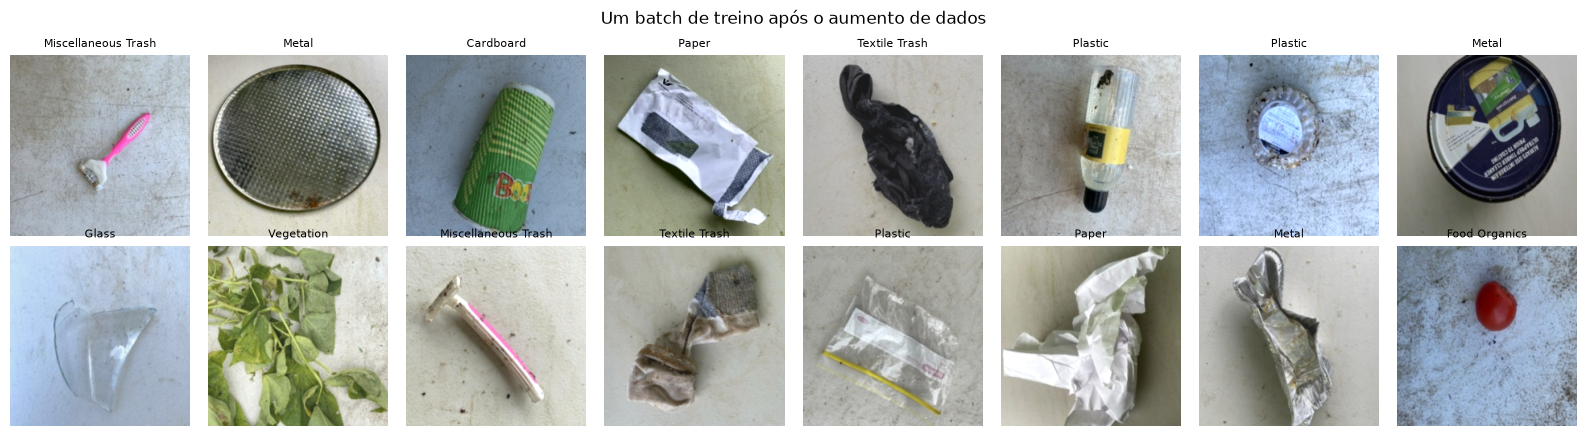

In [13]:
def denormalize(t):
    return (t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()

x, y = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, img, label in zip(axes.flat, x, y):
    ax.imshow(denormalize(img)); ax.set_title(CLASSES[label], fontsize=8); ax.axis("off")
plt.suptitle("Um batch de treino após o aumento de dados")
plt.tight_layout()
plt.show()

## 3. Transfer learning com base congelada (condição de referência)

**Decisões:**
- **Classificador novo:** o original (`Dropout(0,2) → Linear(1280, 1000)`) é trocado por `Dropout(0,2) → Linear(1280, 9)`.
  Mantemos o mesmo dropout do artigo; uma única camada linear basta porque as 1.280 features da base já são de alto nível — uma cabeça maior só adicionaria parâmetros e risco de overfitting com 3,3 mil imagens.
- **Base congelada:** `requires_grad = False` em todo `model.features`.
- **BatchNorm congelada:** as camadas de BatchNorm da base ficam em modo `eval` durante o treino. Sem isso, mesmo com pesos congelados,
  as médias e variâncias aprendidas no ImageNet seriam sobrescritas pelas estatísticas dos nossos batches — a base deixaria de estar realmente congelada.
- **Função de erro:** `CrossEntropyLoss` ponderada pelos pesos de classe da Seção 2.6.
- **Otimizador:** Adam, lr = 1e-3 (valor padrão e adequado para treinar uma camada nova do zero), batch 32.
- **Seleção e parada:** a cada época avaliamos o **F1-macro na validação**; guardamos o melhor checkpoint e paramos se não houver melhora em 4 épocas (máx. 15).
  A mesma regra será usada nas estratégias A e B.


In [14]:
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

def build_model():
    model = mobilenet_v2(weights=WEIGHTS)
    model.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(model.last_channel, len(CLASSES)))
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

torch.manual_seed(SEED)
frozen_model = build_model()
for p in frozen_model.features.parameters():
    p.requires_grad = False

total, trainable = count_params(frozen_model)
print(f"Parâmetros totais: {total:,} | treináveis: {trainable:,} ({trainable / total:.2%})")
print(frozen_model.classifier)

Parâmetros totais: 2,235,401 | treináveis: 11,529 (0.52%)
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=9, bias=True)
)


In [15]:
# dimensões de cada estágio para uma imagem 224×224×3
rows, x = [], torch.zeros(1, 3, 224, 224)
frozen_model.eval()
with torch.no_grad():
    for i, layer in enumerate(frozen_model.features):
        x = layer(x)
        rows.append({"camada": f"features[{i}]", "tipo": type(layer).__name__, "saída": tuple(x.shape[1:]),
                     "parâmetros": sum(p.numel() for p in layer.parameters())})
    out = frozen_model(torch.zeros(1, 3, 224, 224))
print("Entrada: (3, 224, 224) → saída:", tuple(out.shape[1:]), "(um logit por classe)")
pd.DataFrame(rows)

Entrada: (3, 224, 224) → saída: (9,) (um logit por classe)


,camada,tipo,saída,parâmetros
0,features[0],Conv2dNormActivation,"(32, 112, 112)",928
1,features[1],InvertedResidual,"(16, 112, 112)",896
2,features[2],InvertedResidual,"(24, 56, 56)",5136
3,features[3],InvertedResidual,"(24, 56, 56)",8832
4,features[4],InvertedResidual,"(32, 28, 28)",10000
5,features[5],InvertedResidual,"(32, 28, 28)",14848
6,features[6],InvertedResidual,"(32, 28, 28)",14848
7,features[7],InvertedResidual,"(64, 14, 14)",21056
8,features[8],InvertedResidual,"(64, 14, 14)",54272
9,features[9],InvertedResidual,"(64, 14, 14)",54272


### 3.1 Funções de treino e avaliação

Escritas uma única vez e reutilizadas sem alteração nas estratégias A e B — garante que as três condições sejam treinadas e avaliadas da mesma forma.

Treinar no CPU leva dezenas de minutos por condição. Para reexecutar o notebook sem repetir treinos, `fit` salva checkpoint, histórico e tempo em `models/`
e, se já existirem, apenas os recarrega (`FORCE_RETRAIN = True` refaz tudo).


In [16]:
FORCE_RETRAIN = False

def set_train_mode(model):
    # BatchNorm de camadas congeladas fica em eval para não alterar as estatísticas do ImageNet
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    set_train_mode(model) if training else model.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            y_true += y.tolist()
            y_pred += logits.argmax(1).tolist()
    return total_loss / len(y_true), f1_score(y_true, y_pred, average="macro")

def fit(model, optimizer, name, max_epochs=15, patience=4):
    ckpt, hist_file, info_file = (MODELS_DIR / f"{name}{ext}" for ext in (".pt", "_history.csv", "_info.json"))
    if ckpt.exists() and hist_file.exists() and info_file.exists() and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ckpt))
        print(f"{name}: checkpoint existente carregado (FORCE_RETRAIN=False)")
        return pd.read_csv(hist_file), pd.read_json(info_file, typ="series").to_dict()

    best_f1, wait, history, start = -1.0, 0, [], time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_f1 = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_f1 = run_epoch(model, val_loader, criterion)
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_f1=tr_f1, val_f1=va_f1))
        print(f"{name} | época {epoch:2d} | loss treino {tr_loss:.3f} val {va_loss:.3f} | "
              f"F1-macro treino {tr_f1:.3f} val {va_f1:.3f} | {time.perf_counter() - start:5.0f}s")
        if va_f1 > best_f1:
            best_f1, wait = va_f1, 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= patience:
                print(f"early stopping: {patience} épocas sem melhora")
                break

    info = dict(name=name, epochs_run=epoch, best_epoch=int(np.argmax([h["val_f1"] for h in history]) + 1),
                best_val_f1=best_f1, train_seconds=round(time.perf_counter() - start, 1),
                trainable_params=count_params(model)[1])
    history = pd.DataFrame(history)
    history.to_csv(hist_file, index=False)
    pd.Series(info).to_json(info_file)
    model.load_state_dict(torch.load(ckpt))  # devolve o modelo da melhor época
    return history, info

@torch.no_grad()
def predict(model, loader):
    model.eval()
    return torch.cat([model(x).softmax(1) for x, _ in loader]).numpy()

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for col, ax in (("loss", ax1), ("f1", ax2)):
        ax.plot(history.epoch, history[f"train_{col}"], "o-", label="treino")
        ax.plot(history.epoch, history[f"val_{col}"], "o-", label="validação")
        ax.set_xlabel("época"); ax.set_ylabel("loss" if col == "loss" else "F1-macro"); ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def val_metrics(probs):
    pred = probs.argmax(1)
    return {"acurácia": accuracy_score(y_val, pred), "acurácia balanceada": balanced_accuracy_score(y_val, pred),
            "F1-macro": f1_score(y_val, pred, average="macro")}

### 3.2 Treinamento

In [17]:
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights.values, dtype=torch.float32))
optimizer = torch.optim.Adam([p for p in frozen_model.parameters() if p.requires_grad], lr=1e-3)

frozen_history, frozen_info = fit(frozen_model, optimizer, "frozen")
frozen_info

frozen: checkpoint existente carregado (FORCE_RETRAIN=False)


{'name': 'frozen',
 'epochs_run': 15,
 'best_epoch': 13,
 'best_val_f1': 0.8348358604,
 'train_seconds': 1236.8,
 'trainable_params': 11529}

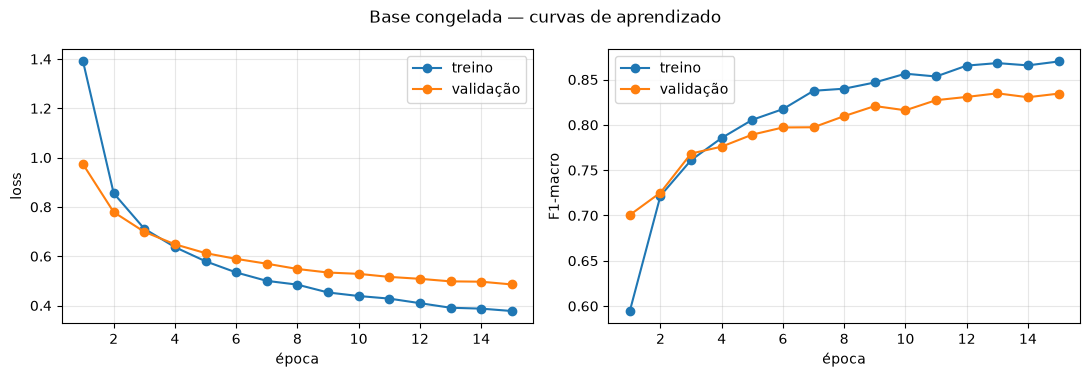

,epoch,train_loss,val_loss,train_f1,val_f1
0,1,1.390,0.973,0.595,0.701
1,2,0.856,0.779,0.722,0.725
2,3,0.712,0.699,0.761,0.768
3,4,0.637,0.648,0.786,0.776
4,5,0.579,0.612,0.806,0.789
5,6,0.534,0.589,0.817,0.797
6,7,0.500,0.570,0.838,0.797
7,8,0.485,0.548,0.840,0.810
8,9,0.453,0.534,0.847,0.821
9,10,0.439,0.528,0.857,0.816


In [18]:
plot_history(frozen_history, "Base congelada — curvas de aprendizado")
frozen_history.round(3)

**Observação sobre as curvas:** a loss e o F1 de *treino* são medidos com aumento de dados e dropout ativos, enquanto os de validação usam imagens limpas e dropout desligado.
Por isso a validação pode ficar **acima** do treino sem que isso seja um erro — o que indica overfitting é o treino melhorando enquanto a validação piora.


**Análise das curvas (base congelada):**
- As duas losses caem de forma contínua e a de validação **ainda descia na época 15** (0,486). Não há sinal de overfitting:
  a validação não piora em nenhum momento, e a diferença de F1 entre treino e validação é pequena (~0,035).
- A melhor época na validação foi a 13 (F1-macro 0,835); de lá até a 15 o ganho praticamente estagnou (±0,004).
- Com apenas **11.529 parâmetros treináveis (0,52%)**, o modelo só consegue combinar features prontas do ImageNet. O platô em ~0,83
  sugere um **leve underfitting por capacidade**: as features genéricas não separam bem alguns materiais. Essa é a motivação do fine-tuning.
- Custo: ~82 s por época em CPU, ~21 min no total.


### 3.3 Resultados na validação

In [19]:
frozen_probs = predict(frozen_model, val_loader)
frozen_pred = frozen_probs.argmax(1)
print(pd.Series(val_metrics(frozen_probs)).round(4).to_string())
print()
print(classification_report(y_val, frozen_pred, target_names=CLASSES, digits=3))

acurácia               0.8345
acurácia balanceada    0.8432
F1-macro               0.8348

                     precision    recall  f1-score   support

          Cardboard      0.831     0.855     0.843        69
      Food Organics      0.857     0.885     0.871        61
              Glass      0.750     0.857     0.800        63
              Metal      0.897     0.874     0.885       119
Miscellaneous Trash      0.688     0.743     0.714        74
              Paper      0.765     0.827     0.795        75
            Plastic      0.904     0.754     0.822       138
      Textile Trash      0.820     0.854     0.837        48
         Vegetation      0.954     0.939     0.947        66

           accuracy                          0.835       713
          macro avg      0.830     0.843     0.835       713
       weighted avg      0.840     0.835     0.835       713



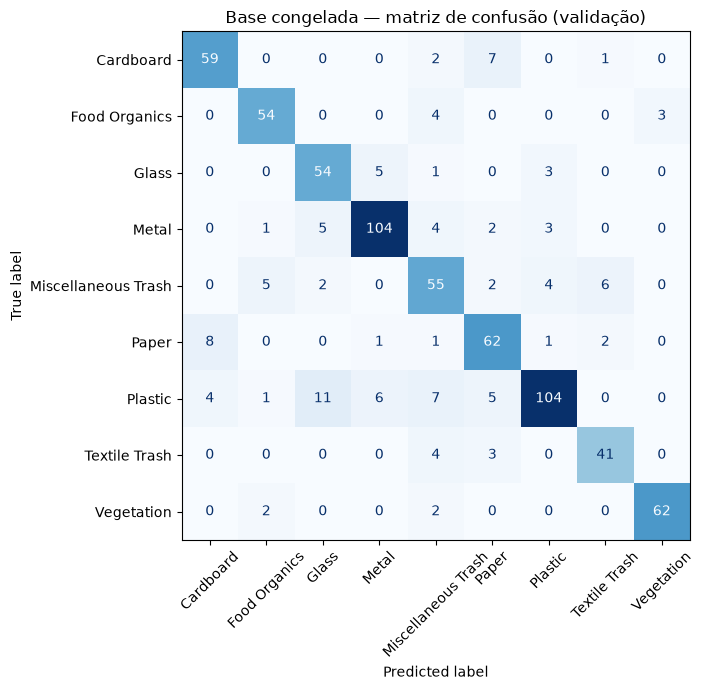

In [20]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_val, frozen_pred, display_labels=CLASSES, xticks_rotation=45,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Base congelada — matriz de confusão (validação)")
plt.tight_layout()
plt.show()

### 3.4 Erros mais graves para a triagem

Agrupamos as classes em **recicláveis** (Cardboard, Glass, Metal, Paper, Plastic) e **não recicláveis** (Food Organics, Miscellaneous Trash, Textile Trash, Vegetation)
para contar os dois tipos de erro definidos na Seção 2.7.


In [21]:
RECYCLABLE = {"Cardboard", "Glass", "Metal", "Paper", "Plastic"}
is_recyclable = np.array([c in RECYCLABLE for c in CLASSES])

def triage_errors(pred):
    lost = (is_recyclable[y_val] & ~is_recyclable[pred]).sum()
    contaminated = (~is_recyclable[y_val] & is_recyclable[pred]).sum()
    return {"reciclável perdido (→ rejeito)": int(lost), "contaminação (rejeito → reciclável)": int(contaminated)}

triage_errors(frozen_pred)

{'reciclável perdido (→ rejeito)': 20,
 'contaminação (rejeito → reciclável)': 11}

### 3.5 Análise visual preliminar

In [22]:
def top_confusions(pred, n=8):
    errors = pd.DataFrame({"real": np.array(CLASSES)[y_val], "previsto": np.array(CLASSES)[pred]})
    errors = errors[errors.real != errors.previsto]
    return errors.value_counts().head(n).rename("qtd").reset_index()

def show_examples(idx, probs, title, n_cols=6):
    idx = list(idx)
    n_rows = int(np.ceil(len(idx) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.3, n_rows * 3.0), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        pred = probs[i].argmax()
        ax.imshow(Image.open(DATA_DIR / val_df.path.iloc[i]))
        ax.set_title(f"real: {CLASSES[y_val[i]]}\nprev: {CLASSES[pred]} ({probs[i, pred]:.2f})", fontsize=8,
                     color="green" if pred == y_val[i] else "red")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

top_confusions(frozen_pred)

,real,previsto,qtd
0,Plastic,Glass,11
1,Paper,Cardboard,8
2,Cardboard,Paper,7
3,Plastic,Miscellaneous Trash,7
4,Plastic,Metal,6
5,Miscellaneous Trash,Textile Trash,6
6,Metal,Glass,5
7,Glass,Metal,5


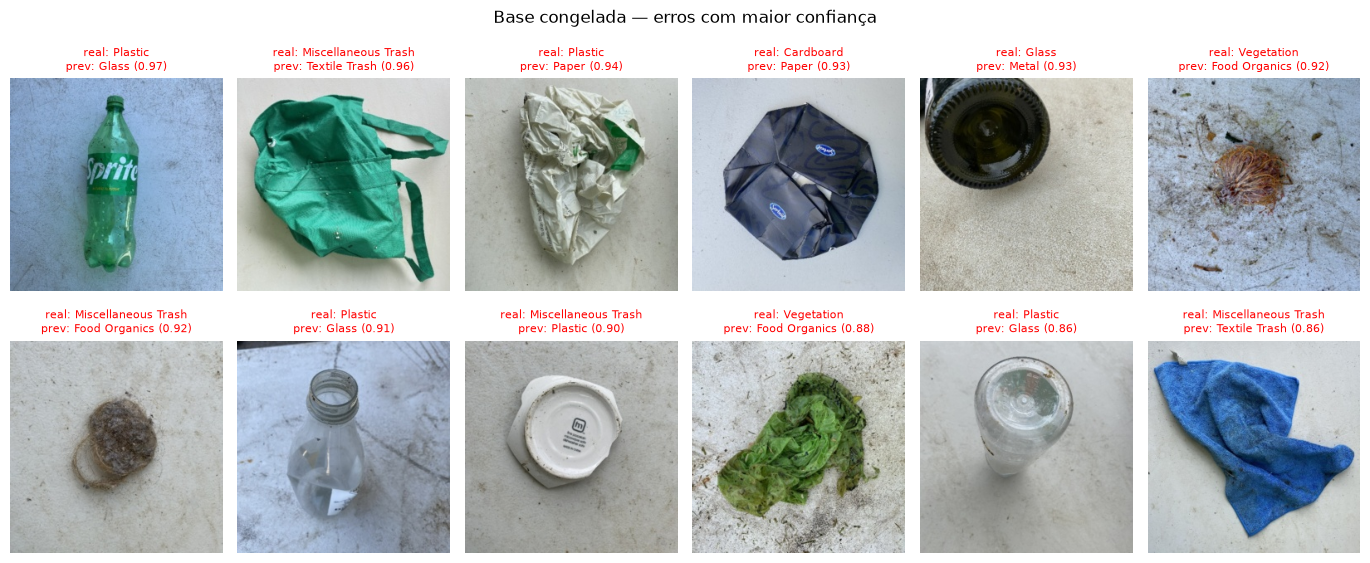

In [23]:
rng = np.random.default_rng(SEED)
wrong = np.flatnonzero(frozen_pred != y_val)
# erros mais "confiantes" primeiro: são os mais preocupantes
wrong_sorted = wrong[np.argsort(-frozen_probs[wrong].max(1))]
show_examples(wrong_sorted[:12], frozen_probs, "Base congelada — erros com maior confiança")

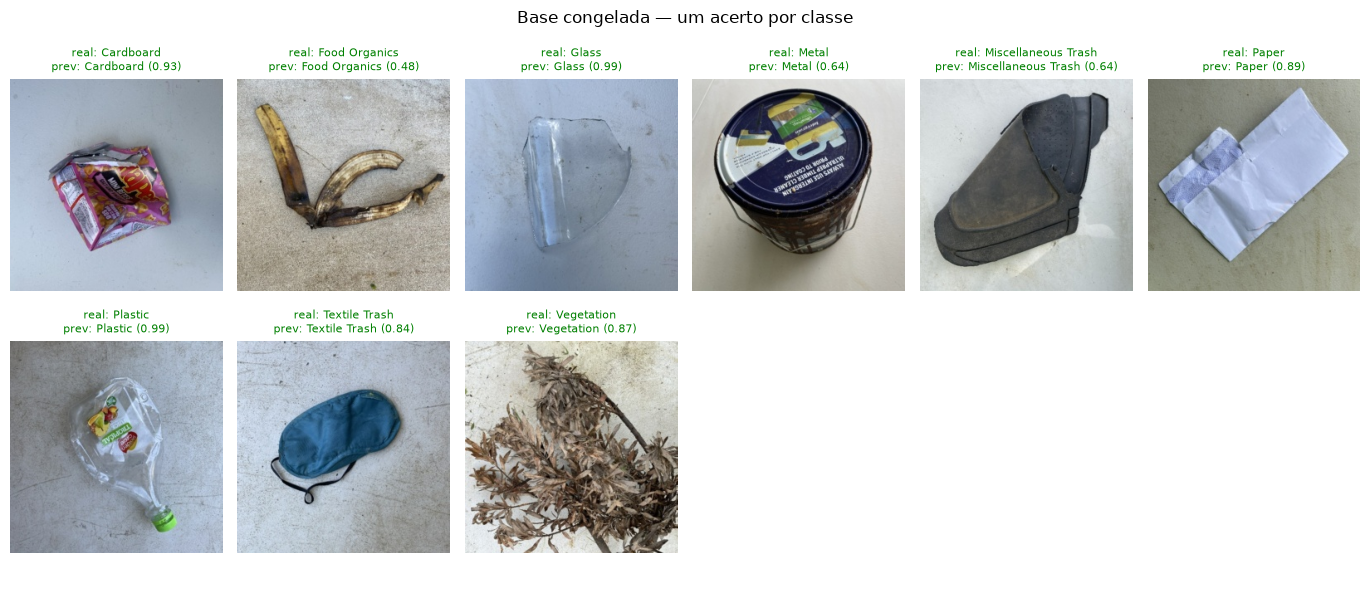

In [24]:
right = np.flatnonzero(frozen_pred == y_val)
one_right_per_class = [rng.choice(right[y_val[right] == k]) for k in range(len(CLASSES)) if (y_val[right] == k).any()]
show_examples(one_right_per_class, frozen_probs, "Base congelada — um acerto por classe")

**Análise preliminar dos resultados na validação (base congelada):**

- **Desempenho geral:** F1-macro 0,835, acurácia 0,835, acurácia balanceada 0,843. Os valores próximos mostram que os pesos de classe
  evitaram que as classes grandes dominassem.
- **Melhores classes:** Vegetation (F1 0,947) e Metal (0,885), que têm forma ou brilho característicos.
- **Piores classes:**
  - *Miscellaneous Trash* (0,714): é uma classe "resto", visualmente heterogênea por definição.
  - *Paper* (0,795) e *Glass* (0,800): o Glass tem precisão baixa (0,75) porque **recebe** garrafas plásticas.
- **Plastic tem o pior recall (0,754):** é confundido com Glass (11), Miscellaneous Trash (7) e Metal (6). Duas hipóteses:
  1. A diferença entre PET transparente e vidro é de **material** (reflexo, espessura), não de forma. As features genéricas do ImageNet
     codificam forma: "garrafa" é garrafa.
  2. Plastic é a maior classe e recebeu o menor peso na loss (0,573), o que pode ter deixado o modelo menos "atento" a ela.
- **Paper ↔ Cardboard (8 + 7) é simétrico:** é ambiguidade real entre classes vizinhas (papel cartão, embalagens), não um viés para um dos lados.
- **Erros com alta confiança:**
  - A garrafa PET da Sprite foi prevista como Glass com 0,97.
  - Um saco verde de pano rotulado *Miscellaneous Trash* foi previsto como Textile (0,96). Nesse caso o rótulo do dataset é discutível,
    e o modelo pode estar "certo".
  - A imagem rotulada *Cardboard* parece um saco plástico/metalizado: indício de **ruído de rotulagem**.
- **Erros da triagem:** 20 recicláveis seriam perdidos para o rejeito e 11 rejeitos contaminariam o fluxo reciclável (de 713 imagens).
  A maior parte das perdas vem do Plastic indo para Miscellaneous Trash.

**O que esperamos do fine-tuning:** melhorar principalmente Plastic × Glass e Paper × Cardboard, onde a distinção depende de textura
e reflexo do material, informação que as camadas finais pré-treinadas no ImageNet não priorizam.


## 4. Fine-tuning — estratégias planejadas

Ambas partem de **cópias de `models/frozen.pt`**, com os mesmos dados, aumentos, pesos de classe, batch, função de erro, seed e regra de seleção/parada (F1-macro na validação, paciência 4, máx. 15 épocas).
O que muda entre elas é **quanto da base é ajustado** e **com qual taxa de aprendizagem**:

| | Estratégia A — descongelamento parcial | Estratégia B — descongelamento total com LR discriminativa |
|---|---|---|
| Camadas treináveis | `features[14:]` (estágio final em 7×7: blocos de 160 e 320 canais + conv 1×1 de 1280) + classificador | toda a base + classificador |
| Taxa de aprendizagem | 1e-4 em tudo que é treinável | base: 1e-5 · classificador: 1e-4 |
| BatchNorm | congeladas em `features[:14]`, atualizadas no estágio final | todas atualizadas |
| Hipótese | As features finais são as mais específicas do ImageNet (objetos, animais); ajustá-las ao domínio de resíduos deve trazer ganho com baixo risco de esquecer filtros genéricos (bordas, texturas) | A base inteira se adapta ao domínio (texturas de lixo sujo, iluminação da esteira), mas a LR 10× menor na base protege os pesos pré-treinados; mais custo e mais risco de overfitting |

**Por que LR menor no fine-tuning:** os pesos pré-treinados já estão num bom ponto; uma LR alta (1e-3) provocaria grandes atualizações e poderia destruir as features aprendidas (*catastrophic forgetting*).
